# Tyre degradation v4: race fixed-effects headline

This notebook runs the v4 analysis from the configured Postgres `clean_laps` view. Corrected race fixed-effects slopes are the headline estimates; within-stint slopes are shown only as a fuel-sensitivity check. The pipeline also tests fuel mismatch, synthetic recovery, low-data handling, and held-out validation, then writes the reports and model artifact.

Run every cell from top to bottom. The analysis fits the race fixed-effects design under three fuel assumptions and performs race-clustered sensitivity intervals.

In [1]:
from pathlib import Path
import os
import sys

working_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (working_directory, *working_directory.parents)
        if (candidate / "pyproject.toml").is_file()
        and (candidate / "src" / "f1engine").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the f1-telemetry-engine project root.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from f1engine.tyre_model_v4 import run_analysis

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\Taksh Doshi\OneDrive\Desktop\f1-telemetry-engine


## Run the v4 pipeline

This reads the race-lap view and regenerates `docs/results_v4.md`, `docs/model_results.md`, and `models/tyre_degradation_v4.joblib`.

In [2]:
results = run_analysis()
display(pd.Series(results["summary"], name="value").to_frame())
print(f"Artifact: {results['artifact_path']}")
print("Reports: docs/results_v4.md and docs/model_results.md")

Skipping race 2022-19: corrected fixed-effects design rank 69/70.


Skipping race 2022-7: corrected fixed-effects design rank 75/76.


Skipping race 2023-4: corrected fixed-effects design rank 70/71.


Skipping race 2023-9: corrected fixed-effects design rank 89/90.


Skipping race 2024-16: corrected fixed-effects design rank 75/76.


Skipping race 2024-9: corrected fixed-effects design rank 46/47.


... (10 outputs left out)

Skipping race 2024-16: corrected fixed-effects design rank 75/76.


Skipping race 2024-9: corrected fixed-effects design rank 46/47.


,value
source_rows,60706
usable_rows,60227
races,66
low_data_races,4
full_rank_races,60
rank_deficient_races,6
failed_races,0
eligible_fixed_effect_races,59
minimum_race_clean_laps,500
eligible_race_fixed_effects,167


Artifact: C:\Users\Taksh Doshi\OneDrive\Desktop\f1-telemetry-engine\models\tyre_degradation_v4.joblib
Reports: docs/results_v4.md and docs/model_results.md


## Data accounting and estimator tables

Race fixed-effects slopes are pooled across independent races with random-effects 95% intervals. Only races with at least 500 clean laps and full-rank designs enter headline pools. Low-data and rank-deficient races remain visible below.

In [3]:
display(pd.Series(results["exclusions"], name="count").to_frame())
display(results["fuel_sensitivity"])
display(results["stint_sensitivity"])

status_counts = results["fixed_status"]["status"].value_counts().rename_axis("status").to_frame("races")
display(status_counts)
display(results["fixed_status"].loc[results["fixed_status"]["quality_status"].eq("low_data")])
display(results["global_pools"])
display(results["circuit_pools"])

,count
input_rows,60706
rows_excluded_missing_or_invalid_required_fields,479
missing_values_by_field,"{'year': 0, 'round': 0, 'circuit': 0, 'driver_..."
invalid_numeric_by_field,"{'year': 0, 'round': 0, 'tyre_life': 0, 'stint..."
source_rows_with_unknown_compounds,0
stints_shorter_than_minimum,0
stints_with_multiple_compounds,0
stints_without_tyre_age_variation,0
laps_removed_by_optional_slow_lap_filter,0


,assumed_fuel_effect_s_per_kg,compound,pooled_slope_seconds_per_lap,lower_95,upper_95,race_estimates,negative_race_slope_share,tau_squared,laps,difference_from_0.03
0,0.02,HARD,0.050684,0.043806,0.057562,58,0.068966,0.000626,26995,8.326673e-17
1,0.02,MEDIUM,0.062653,0.053905,0.071401,58,0.034483,0.001009,20784,3.885781e-16
2,0.02,SOFT,0.090187,0.074409,0.105965,51,0.117647,0.002091,7576,-5.551115e-17
3,0.03,HARD,0.050684,0.043806,0.057562,58,0.068966,0.000626,26995,0.000000e+00
4,0.03,MEDIUM,0.062653,0.053905,0.071401,58,0.034483,0.001009,20784,0.000000e+00
5,0.03,SOFT,0.090187,0.074409,0.105965,51,0.117647,0.002091,7576,0.000000e+00
6,0.04,HARD,0.050684,0.043806,0.057562,58,0.068966,0.000626,26995,3.053113e-16
7,0.04,MEDIUM,0.062653,0.053905,0.071401,58,0.034483,0.001009,20784,4.024558e-16
8,0.04,SOFT,0.090187,0.074409,0.105965,51,0.117647,0.002091,7576,-8.326673e-17


,assumed_fuel_effect_s_per_kg,compound,pooled_slope_seconds_per_lap,lower_95,upper_95,median_slope_seconds_per_lap,negative_stint_slope_share,stints,races,bootstrap_replicates,weighting
0,0.02,HARD,0.021704,0.007848,0.033423,0.035635,0.259574,1175,64,1000,stint lap count
1,0.02,MEDIUM,0.022061,-0.003262,0.044542,0.043435,0.295630,1167,65,1000,stint lap count
2,0.02,SOFT,0.022906,-0.054810,0.090451,0.069035,0.189765,469,39,1000,stint lap count
3,0.03,HARD,0.040463,0.027382,0.052377,0.052974,0.177872,1175,64,1000,stint lap count
4,0.03,MEDIUM,0.040425,0.013706,0.065536,0.060755,0.233933,1167,65,1000,stint lap count
5,0.03,SOFT,0.040933,-0.036111,0.109654,0.085990,0.130064,469,39,1000,stint lap count
6,0.04,HARD,0.059221,0.046335,0.070786,0.071499,0.101277,1175,64,1000,stint lap count
7,0.04,MEDIUM,0.058789,0.032248,0.080951,0.079126,0.173950,1167,65,1000,stint lap count
8,0.04,SOFT,0.058959,-0.016396,0.124422,0.103493,0.095949,469,39,1000,stint lap count


,races
status,
full_rank,60
rank_deficient,6
no_clean_laps,2


,year,round,circuit,raw_laps,wet_compound_laps,safety_or_red_flag_laps,pit_laps,opening_laps,race_id,clean_laps,design_rank,design_columns,condition_number,status,quality_status,low_data_reason
18,2022,17,Singapore Grand Prix,945,588,219,45,20,2022-17,277,44.0,44.0,1.600513e+03,full_rank,low_data,277 clean laps; minimum is 500. Raw lap filter...
19,2024,9,Canadian Grand Prix,1272,846,186,89,20,2024-9,318,46.0,47.0,6.565938e+16,rank_deficient,low_data,318 clean laps; minimum is 500. Raw lap filter...
40,2022,18,Japanese Grand Prix,507,507,38,83,20,2022-18,0,NaN,NaN,NaN,no_clean_laps,low_data,0 clean laps; minimum is 500. Raw lap filters ...
61,2024,21,São Paulo Grand Prix,1134,1134,149,68,18,2024-21,0,NaN,NaN,NaN,no_clean_laps,low_data,0 clean laps; minimum is 500. Raw lap filters ...


,compound,pooled_slope_seconds_per_lap,lower_95,upper_95,race_estimates,negative_race_slope_share,tau_squared,laps
0,HARD,0.050684,0.043806,0.057562,58,0.068966,0.000626,26995
1,MEDIUM,0.062653,0.053905,0.071401,58,0.034483,0.001009,20784
2,SOFT,0.090187,0.074409,0.105965,51,0.117647,0.002091,7576


,circuit,compound,pooled_slope_seconds_per_lap,lower_95,upper_95,race_estimates,negative_race_slope_share,tau_squared,laps
0,Abu Dhabi Grand Prix,HARD,0.057115,0.052354,0.061877,3,0.000000,0.000010,2026
1,Abu Dhabi Grand Prix,MEDIUM,0.080793,0.048099,0.113488,3,0.000000,0.000783,923
2,Australian Grand Prix,HARD,0.009077,-0.033871,0.052024,3,0.333333,0.001319,1957
3,Australian Grand Prix,MEDIUM,0.080140,0.062764,0.097515,3,0.000000,0.000000,461
4,Bahrain Grand Prix,HARD,0.114802,0.097028,0.132577,3,0.000000,0.000189,1335
5,Bahrain Grand Prix,SOFT,0.140828,0.114890,0.166767,3,0.000000,0.000460,1194
6,Belgian Grand Prix,HARD,0.111929,0.045957,0.177902,3,0.000000,0.002529,619
7,Belgian Grand Prix,MEDIUM,0.119545,0.052444,0.186645,3,0.000000,0.003440,1025
8,Belgian Grand Prix,SOFT,0.109287,0.029682,0.188892,3,0.000000,0.004806,473
9,British Grand Prix,HARD,-0.040189,-0.146837,0.066459,3,0.333333,0.008162,306


## Synthetic recovery and held-out evaluation

The evaluations compare fixed-effects pools with a zero-degradation baseline. Leave-one-race-out keeps each race wholly in either training or test data; the chronological evaluation trains on 2022–2023 and tests on 2024. Eligible and low-data race summaries are kept separate.

In [4]:
display(results["synthetic_recovery"])
display(results["validation"])
display(results["per_race_validation"])
display(results["chronological_validation"])
display(results["fuel_mismatch"])

,method,compound,true_slope,recovered_slope,error,full_rank_races,rank,columns
0,Primary stint slopes,SOFT,0.10,0.099695,-0.000305,12,NaN,NaN
1,Corrected race fixed effects,SOFT,0.10,0.099691,-0.000309,12,NaN,NaN
2,Primary stint slopes,MEDIUM,0.06,0.059341,-0.000659,12,NaN,NaN
3,Corrected race fixed effects,MEDIUM,0.06,0.059509,-0.000491,12,NaN,NaN
4,Primary stint slopes,HARD,0.03,0.030308,0.000308,12,NaN,NaN
5,Corrected race fixed effects,HARD,0.03,0.030402,0.000402,12,NaN,NaN
6,Flawed v2 design,all,NaN,NaN,NaN,0,121.0,124.0


,validation,data_group,races,laps,stints,baseline_relative_mae_seconds,model_relative_mae_seconds,cross_circuit_fallback_stints
0,leave-one-race-out,eligible,64,57906,2779,1.043418,1.019867,2779
1,leave-one-race-out,low_data,2,553,32,3.414911,3.978533,32
2,"train 2022-2023, test 2024",eligible,22,20841,934,0.929220,0.842551,934
3,"train 2022-2023, test 2024",low_data,1,290,18,3.205774,3.774681,18


,race_id,year,round,circuit,clean_laps,quality_status,laps,stints,baseline_relative_mae_seconds,model_relative_mae_seconds,cross_circuit_fallback_stints
0,2022-1,2022,1,Bahrain Grand Prix,893,eligible,748,55,1.074679,0.696458,55
1,2022-10,2022,10,British Grand Prix,676,eligible,656,41,1.567028,1.792812,41
2,2022-11,2022,11,Austrian Grand Prix,843,eligible,839,42,0.966264,0.550733,42
3,2022-12,2022,12,French Grand Prix,833,eligible,800,39,0.678968,0.545087,39
4,2022-13,2022,13,Hungarian Grand Prix,1203,eligible,1200,59,0.964918,0.683769,59
...,...,...,...,...,...,...,...,...,...,...,...
61,2024-5,2024,5,Chinese Grand Prix,762,eligible,669,42,0.960666,0.574596,42
62,2024-6,2024,6,Miami Grand Prix,934,eligible,913,43,0.511029,0.577097,43
63,2024-7,2024,7,Emilia Romagna Grand Prix,1164,eligible,1136,40,1.241928,0.544340,40
64,2024-8,2024,8,Monaco Grand Prix,1187,eligible,1178,21,2.305063,3.729506,21


,race_id,year,round,circuit,clean_laps,quality_status,laps,stints,baseline_relative_mae_seconds,model_relative_mae_seconds,cross_circuit_fallback_stints
0,2024-1,2024,1,Bahrain Grand Prix,1024,eligible,1010,60,0.849879,0.503069,60
1,2024-10,2024,10,Spanish Grand Prix,1206,eligible,1192,60,0.978109,0.574743,60
2,2024-11,2024,11,Austrian Grand Prix,1269,eligible,1263,61,0.949034,0.462067,61
3,2024-12,2024,12,British Grand Prix,662,eligible,651,37,1.441880,1.199328,37
4,2024-13,2024,13,Hungarian Grand Prix,1254,eligible,1209,49,1.044873,0.707033,49
5,2024-14,2024,14,Belgian Grand Prix,751,eligible,712,46,0.583381,0.443753,46
6,2024-15,2024,15,Dutch Grand Prix,1354,eligible,1354,46,0.970416,0.499881,46
7,2024-16,2024,16,Italian Grand Prix,927,eligible,918,47,0.612740,0.517152,47
8,2024-17,2024,17,Azerbaijan Grand Prix,881,eligible,881,36,0.639759,0.805275,36
9,2024-18,2024,18,Singapore Grand Prix,1109,eligible,1099,40,0.884721,0.711344,40


,true_fuel_effect_s_per_kg,assumed_fuel_effect_s_per_kg,method,compound,true_slope,estimated_slope,bias,correct_assumption_slope,fuel_mismatch_bias,max_slope_change_across_assumptions
0,0.04,0.02,Stint slopes,SOFT,0.10,0.063212,-0.036788,0.099879,-0.036667,NaN
1,0.04,0.02,Stint slopes,MEDIUM,0.06,0.024486,-0.035514,0.061152,-0.036667,NaN
2,0.04,0.02,Stint slopes,HARD,0.03,-0.006595,-0.036595,0.030071,-0.036667,NaN
3,0.04,0.02,Race fixed effects,SOFT,0.10,0.098716,-0.001284,NaN,NaN,5.551115e-16
4,0.04,0.03,Race fixed effects,SOFT,0.10,0.098716,-0.001284,NaN,NaN,5.551115e-16
5,0.04,0.04,Race fixed effects,SOFT,0.10,0.098716,-0.001284,NaN,NaN,5.551115e-16
6,0.04,0.02,Race fixed effects,MEDIUM,0.06,0.060267,0.000267,NaN,NaN,1.131040e-15
7,0.04,0.03,Race fixed effects,MEDIUM,0.06,0.060267,0.000267,NaN,NaN,1.131040e-15
8,0.04,0.04,Race fixed effects,MEDIUM,0.06,0.060267,0.000267,NaN,NaN,1.131040e-15
9,0.04,0.02,Race fixed effects,HARD,0.03,0.029743,-0.000257,NaN,NaN,9.575674e-16


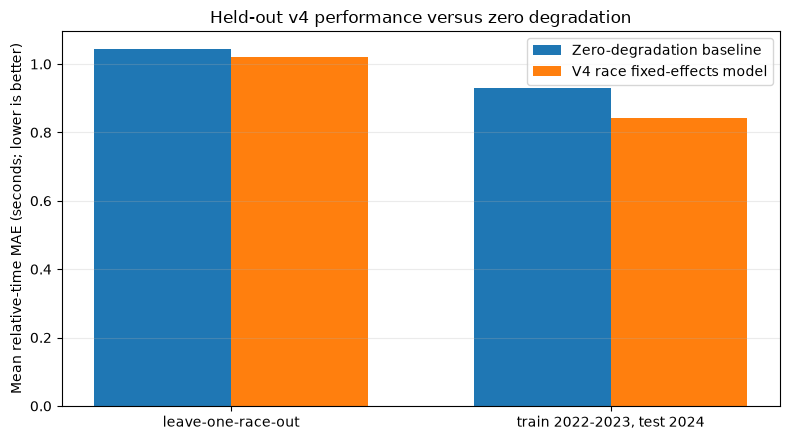

In [5]:
evaluation = results["validation"].loc[
    results["validation"]["data_group"].eq("eligible")
].reset_index(drop=True)
labels = evaluation["validation"].tolist()
x = range(len(evaluation))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    [value - width / 2 for value in x],
    evaluation["baseline_relative_mae_seconds"],
    width,
    label="Zero-degradation baseline",
)
ax.bar(
    [value + width / 2 for value in x],
    evaluation["model_relative_mae_seconds"],
    width,
    label="V4 race fixed-effects model",
)
ax.set_xticks(list(x), labels)
ax.set_ylabel("Mean relative-time MAE (seconds; lower is better)")
ax.set_title("Held-out v4 performance versus zero degradation")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Limitations

- Fuel correction assumes a 110 kg starting load and a fixed time-per-kg effect; these are approximate, not measured.
- Within-stint slopes can still absorb track evolution, traffic, weather, setup, and tyre management. Only stints with at least eight clean laps are fitted, and shorter stints are excluded.
- Bootstrap uncertainty resamples whole races, but it does not remove model misspecification. The compound labels are weekend-relative SOFT/MEDIUM/HARD, not the underlying Pirelli C1–C5 rubber.
- Drivers may pit before tyres fall off, creating survivorship bias. Circuit estimates with fewer than three race clusters fall back to cross-circuit pools.
- Race-lap fixed effects absorb the shared linear fuel trend, while stint slopes remain sensitive to the assumed fuel effect.
- The 500-clean-lap and three-full-rank-race rules limit coverage. Weekend-relative compound labels are not Pirelli C1-C5 rubber, and drivers may pit before wear becomes observable, creating survivorship bias.
- Even when held-out MAE improves on a zero-degradation baseline, these estimates are exploratory, not causal wear rates or pit-strategy advice.